In [1]:
import polars as pl

df = pl.read_csv("data/ufcstats_data.csv")
df2 = pl.read_csv("data/ufc_fights.csv")

# Convert literal string "NA"
df = df.with_columns([
    pl.when(pl.col(c) == "NA").then(None).otherwise(pl.col(c)).alias(c)
    for c in df.columns if df[c].dtype == pl.String
])

# Fix Percentages
pct_columns = ["str_acc", "str_def", "td_acc", "td_def"]
for col in pct_columns:
    df = df.with_columns(
        pl.col(col)
        .str.replace("%", "", literal=True)
        .cast(pl.Float64)
    )

# Weight
df = df.with_columns(
    pl.col("weight")
    .str.replace(" lbs.", "", literal=True)
    .cast(pl.Int64)
)

# Reach
df = df.with_columns(
    pl.col("reach")
    .str.replace('"', '', literal=True)
    .cast(pl.Float64)
)

df = df.with_columns(
    pl.when((pl.col("wins") + pl.col("losses") + pl.col("draws")) == 0)
    .then(0.0)
    .otherwise((pl.col("wins") / (pl.col("wins") + pl.col("losses") + pl.col("draws")) * 100).round(1))
    .alias("win_rate")
)

#second dataset fix date
df2 = df2.with_columns(
    pl.col("date")
    .str.strptime(pl.Date, format="%Y-%m-%d", strict=False)
    .dt.year()
    .alias("fight_year")
)

timeline_df = (
    df2.filter(pl.col("fight_year").is_not_null())
    .group_by("fight_year")
    .agg([
        pl.len().alias("total_fights"),
        (pl.col("method").filter(pl.col("method").str.contains("Decision")).len() / pl.len() * 100).alias("decision_pct")
    ])
    .sort("fight_year")
)

print(f"Fighter Dataset Shape: {df.shape} | Fight History Dataset Shape: {df2.shape}")

# Primary Dataset (ufcstats_data.csv)
print("\n-----------------------")
df.glimpse()
print("\nFighter Dataset Null Counts:")
print(df.null_count())
print("\nFighter Dataset Description:")
print(df.describe())

# Other primary Dataset (ufc_fights.csv)
print("\n----------------------")
df2.glimpse()
print("\nFight History Dataset Null Counts:")
print(df2.null_count())
print("\nFight History Dataset Description:")
print(df2.describe())

Fighter Dataset Shape: (4504, 19) | Fight History Dataset Shape: (8736, 16)

-----------------------
Rows: 4504
Columns: 19
$ name     <str> 'Tom Aaron', 'Danny Abbadi', 'Nariman Abbasov', 'Darion Abbey', 'David Abbott', 'Hamdy Abdelwahab', 'Farida Abdueva', 'Mansur Abdul-Malik', 'Tahir Abdullayev', 'Shamil Abdurakhimov'
$ wins     <i64> 5, 4, 28, 9, 10, 7, 8, 9, 20, 20
$ losses   <i64> 3, 6, 4, 5, 15, 1, 0, 1, 3, 8
$ draws    <i64> 0, 0, 0, 0, 0, 0, 0, 1, 0, 0
$ nc       <i64> 0, 0, 0, 0, 0, 1, 1, 0, 0, 0
$ height   <str> null, '5\' 11"', '5\' 8"', '6\' 2"', '6\' 0"', '6\' 2"', '5\' 3"', '6\' 2"', '5\' 8"', '6\' 3"'
$ weight   <i64> 155, 155, 155, 265, 265, 265, 115, 185, 170, 235
$ reach    <f64> null, null, 66.0, 80.0, null, 72.0, 66.0, 80.0, 73.0, 76.0
$ stance   <str> null, 'Orthodox', 'Orthodox', 'Orthodox', 'Switch', 'Southpaw', 'Orthodox', 'Orthodox', 'Orthodox', 'Orthodox'
$ dob      <str> 'Jul 13, 1978', 'Jul 03, 1983', 'Feb 01, 1994', 'Feb 25, 1993', 'Apr 26, 1965', 'Jan 22,

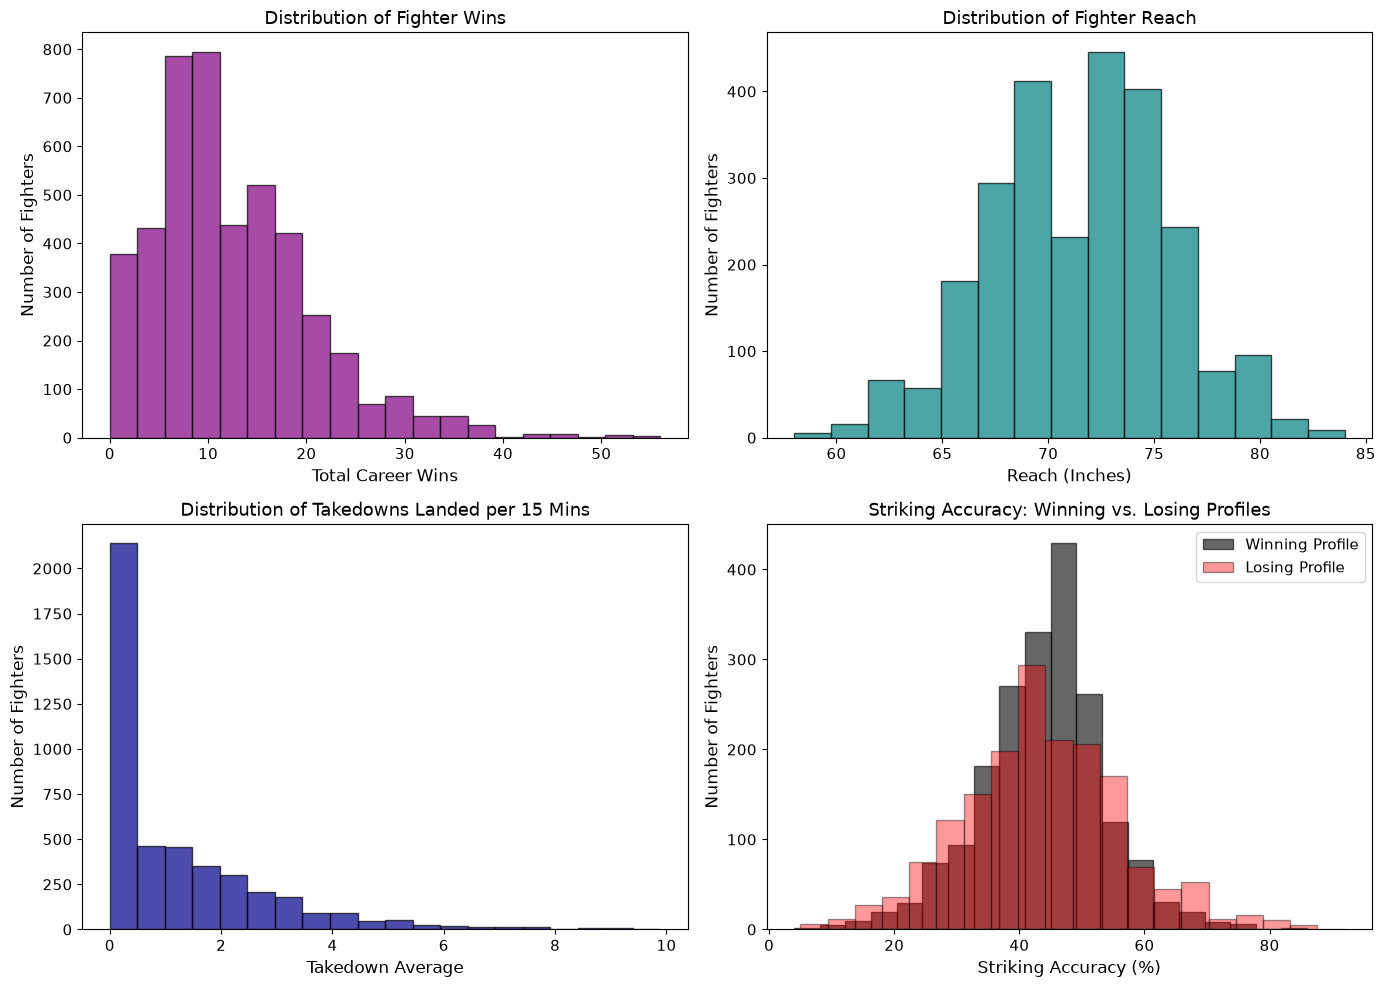

In [2]:
import matplotlib.pyplot as plt
import polars as pl

plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13})

fig1, axes_grid = plt.subplots(2, 2, figsize=(14, 10))
axes = axes_grid.flatten()

# Plot 1: Wins Density
wins_data = df.filter(pl.col("wins") < 60)["wins"].to_list()
axes[0].hist(wins_data, bins=20, color="purple", edgecolor="black", alpha=0.7)
axes[0].set_title("Distribution of Fighter Wins")
axes[0].set_xlabel("Total Career Wins")
axes[0].set_ylabel("Number of Fighters")

# Plot 2: Reach
reach_data = df.filter(pl.col("reach").is_not_null())["reach"].to_list()
axes[1].hist(reach_data, bins=15, color="teal", edgecolor="black", alpha=0.7)
axes[1].set_title("Distribution of Fighter Reach")
axes[1].set_xlabel("Reach (Inches)")
axes[1].set_ylabel("Number of Fighters")

# Plot 3: Wrestling Takedowns
td_data = df.filter(pl.col("td_avg") < 10)["td_avg"].to_list()
axes[2].hist(td_data, bins=20, color="darkblue", edgecolor="black", alpha=0.7)
axes[2].set_title("Distribution of Takedowns Landed per 15 Mins")
axes[2].set_xlabel("Takedown Average")
axes[2].set_ylabel("Number of Fighters")

# Plot 4: Striking Accuracy
valid_stats = df.filter((pl.col("str_acc") > 0) & (pl.col("str_acc") < 100))
median_wins = df["wins"].median()
high_winners = valid_stats.filter(pl.col("wins") > median_wins)["str_acc"].to_list()
low_winners = valid_stats.filter(pl.col("wins") <= median_wins)["str_acc"].to_list()

axes[3].hist(high_winners, bins=20, color="black", edgecolor="black", alpha=0.6, label="Winning Profile")
axes[3].hist(low_winners, bins=20, color="red", edgecolor="black", alpha=0.4, label="Losing Profile")
axes[3].set_title("Striking Accuracy: Winning vs. Losing Profiles")
axes[3].set_xlabel("Striking Accuracy (%)")
axes[3].set_ylabel("Number of Fighters")
axes[3].legend()

plt.tight_layout()
plt.show()


Plot 1, the distribution of fighter wins:

Center: Peak is at the median, 10 wins

Spread: Most fall between 0 and 20 wins

Skew: Right skewed

Plot 2, distribution of fighter reach:

Center: Balanced at 72 inches

Spread: Most are between 66 and 76

Skew: Seems to be symmetric

Plot 3, distribution of takedowns landed per 15 mins:

Center: Peak is between 0 and 1

Spread: Between 0 and 6, but most fighters fall at 0

Skew: Right skewed

For plot 4, distribution of striking accuracy:

Center: Losing profile peaks at around 42%, Winning profiles peaks near 50%

Spread: Most are between 20% and 60%

Skew: Symmetric bell curve